# Comparar adaptadores ejecutados con trayectorias archivadas

**Nivel:** 3. **Requisitos previos:** Las lecciones anteriores de este tema; arrays NumPy y evaluación temporal. **Tiempo de lectura:** 50 minutos.

**Pregunta:** ¿Cómo se comparan cuatro adaptadores estadísticos y de árboles ajustados ahora, siete referencias neuronales o preentrenadas recién ejecutadas y trayectorias archivadas separadas sobre el mismo bloque sintético de 12 objetivos?

## Objetivos

Compararemos métodos sin borrar cómo se obtuvieron sus predicciones. La lección ejecuta tres fuentes distintas de evidencia sobre la misma historia sintética y 12 objetivos reservados. Primero ajusta los adaptadores instalados AutoETS, AutoTheta, AutoARIMA acotado y LightGBM. Después el entorno de referencia fijado ajusta realmente NLinear, DLinear y NHITS de NeuralForecast y ejecuta los checkpoints fijados de Chronos-Bolt, Chronos-2, TimesFM-2.5 y TiRex-2. Por separado vuelve a puntuar trayectorias conservadas, incluidas adaptaciones directas en torch. Puntuar una predicción archivada produce un cálculo nuevo, no un ajuste nuevo ni una inferencia del checkpoint.

Examinaremos por separado error puntual y amplitud, conservaremos los nombres originales e identificaremos limitaciones que una clasificación no resuelve. El experimento no demuestra rendimiento poblacional, independencia respecto de datos de preentrenamiento ni precisión de una política productiva. Su propósito más acotado resulta útil: los competidores comparten serie disponible, horizonte, objetivos finales y escala. Así, una diferencia de error no puede atribuirse a bloques de evaluación diferentes.

## Preparación

Las dependencias directas exactas identifican el entorno del notebook y sus proveedores estadísticos y de árboles. El entorno Linux de referencia declarado por separado aporta las siete implementaciones neuronales o preentrenadas; sus versiones comprobadas y revisiones de checkpoints se imprimen junto con las trayectorias nuevas. Prepare ese entorno y sus pesos mediante el flujo documentado antes de ejecutar. Ninguna celda instala paquetes ni sustituye modelos menores.

```text
pip install numpy==2.4.6
pip install scipy==1.15.3
pip install matplotlib==3.10.8
pip install statsforecast==2.0.3
pip install lightgbm==4.6.0
pip install mlforecast==1.0.31
pip install nbformat==5.11.1
pip install nbclient==0.11.0
pip install ipykernel==7.4.0
pip install stumpy==1.14.1
pip install antropy==0.2.2
pip install nolds==0.6.3
pip install pycatch22==0.4.5
pip install scikit-learn==1.9.1
pip install preqts==0.3.0
pip install forecastscope==0.1.4
```


In [1]:
# Configura una sesión portátil; no se descargan datos.
from pathlib import Path
import sys
import json
import warnings
import numpy as np
import matplotlib.pyplot as plt
root = next(p for p in Path.cwd().parents if (p / "VERSION").is_file() and (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
from engine.notebook_reference import reference_forecasts
from engine.model.forecasters import seasonal_naive, ses, holt, holt_winters, theta
from engine.model.forecasters import gaussian_quantiles
from engine.model.context_memory import fit_context_memory
from engine.reevaluation import metrics
from engine.engines.statsforecast_engine import StatsforecastForecaster
from engine.engines.lightgbm_engine import LightGBMForecaster
plt.rcParams.update({"figure.figsize": (8, 3), "figure.dpi": 95, "font.size": 10})
plt.rcParams["svg.hashsalt"] = "chronoscope-lessons"
import importlib.metadata
packages = ("numpy", "scipy", "matplotlib", "statsforecast", "lightgbm", "mlforecast",
            "nbformat", "nbclient", "ipykernel")
for package in packages:
    print(package, importlib.metadata.version(package))

print("ForecastScope", importlib.metadata.version("forecastscope"))


numpy 2.4.6
scipy 1.15.3
matplotlib 3.10.8
statsforecast 2.0.3
lightgbm 4.6.0
mlforecast 1.0.31
nbformat 5.11.1
nbclient 0.11.0
ipykernel 7.4.0
ForecastScope 0.1.4


## Datos

El experimento común de adaptadores utiliza el control sintético TRND_seasonal con tendencia y ciclo, desde `data/derived/TRND_seasonal/trace.json`. ChronoScope es su propietario, bajo MIT; el generador con semilla 42 está en `data-pipeline/engine/cases/forecast_cases.py`. History contiene el prefijo disponible, actual el bloque final consecutivo reservado, seasonality vale 12 observaciones y horizon vale 12 predicciones. Las unidades son generadas. Se distinguen las trayectorias conservadas de las llamadas ejecutadas aquí. Referencias identifica paquetes y modelos; este ejemplo no descarta exposición de los modelos preentrenados a datos semejantes.



In [2]:
# La traza versionada separa la historia disponible del bloque final no observado.
trace = json.loads((root / "data/derived/TRND_seasonal/trace.json").read_text())
history = np.array(trace["history"], dtype=float)
actual = np.array(trace["actual"], dtype=float)
m, h = trace["seasonality"], trace["horizon"]
comparison = json.loads((root / "data/derived/reevaluation.json").read_text())
print('Historia:', len(history), 'Período:', m, 'Bloque reservado:', h)


Historia: 168 Período: 12 Bloque reservado: 12


## Método

AutoETS selecciona una especificación de suavizamiento exponencial mediante statsforecast instalado. El adaptador recibe el período estacional de la traza y convierte las columnas de intervalos analíticos en los cuantiles solicitados. Ejecutar el adaptador real importa: una curva manual con el mismo nombre no reproduciría la selección ni la estimación de parámetros de la biblioteca. La medida obtenida corresponde a esta versión y esta historia, en lugar de una implementación ideal no especificada de la familia ETS.


In [3]:
# Ejecuta el adaptador de referencia instalado con los parámetros ETS publicados.
ets = StatsforecastForecaster("AutoETS", "ets", max_windows=12)
with warnings.catch_warnings(record=True) as notices:
    warnings.filterwarnings("ignore", message="IProgress not found.*")
    warnings.filterwarnings("ignore", category=SyntaxWarning)
    ets_q = ets.quantiles(history, m, h, (0.1, 0.5, 0.9))
print('Avisos de ejecución de AutoETS:', [str(w.message) for w in notices])
print('MASE de AutoETS:', round(metrics(history, actual, ets_q[:, 1], ets_q[:, 0], ets_q[:, 2], m)["mase"], 4))


Avisos de ejecución de AutoETS: []
MASE de AutoETS: 0.6148


AutoTheta también delega el ajuste a la biblioteca de referencia. Es distinto de la función Theta local de historia finita presentada antes. El tratamiento estacional y la selección automáticos pueden modificar el resultado; combinar ambos nombres ocultaría una decisión de implementación. El código imprime la primera predicción para mostrar una salida ejecutada y conserva el origen y horizonte de ETS. Sus parámetros no se eligen después de observar el bloque futuro reservado.


In [4]:
# AutoTheta es una implementación de referencia distinta de la ecuación Theta local.
auto_theta = StatsforecastForecaster("AutoTheta", "theta", max_windows=12)
auto_theta_q = auto_theta.quantiles(history, m, h, (0.1, 0.5, 0.9))
print('Primera predicción de AutoTheta:', round(float(auto_theta_q[0, 1]), 4))


Primera predicción de AutoTheta: 125.8693


AutoARIMA emplea la configuración acotada publicada: búsqueda por pasos, ajuste aproximado y contexto máximo de trescientas sesenta observaciones. Estas decisiones hacen viable el cálculo y forman parte del método evaluado. No representan una búsqueda exhaustiva de órdenes estacionales. Una alternativa más lenta constituiría otro experimento, con tiempo y procedencia propios. Los avisos numéricos, incluidos problemas de convergencia, se capturan e imprimen sin rutas de máquina. Una predicción con ese aviso no demuestra un óptimo exitoso. Cualquier excepción o salida no finita impide completar limpiamente el notebook.


In [5]:
# Ajusta la configuración AutoARIMA aproximada con búsqueda acotada.
arima = StatsforecastForecaster("AutoARIMA", "arima", max_windows=3, ctx_cap=360)
with warnings.catch_warnings(record=True) as notices:
    warnings.simplefilter("always")
    arima_q = arima.quantiles(history, m, h, (0.1, 0.5, 0.9))
print('Avisos de ejecución de AutoARIMA:', sorted(set(str(w.message) for w in notices)))
print('Primera predicción de AutoARIMA:', round(float(arima_q[0, 1]), 4))


Avisos de ejecución de AutoARIMA: ['possible convergence problem: minimize gave code 2]']
Primera predicción de AutoARIMA: 117.0052


LightGBM convierte valores pasados en variables de rezago y predice recursivamente mediante MLForecast. La configuración utiliza cien árboles, treinta y una hojas y tasa de aprendizaje de cinco centésimas. Su objetivo puntual no es regresión de cuantiles. El adaptador estima una desviación residual y construye intervalos gaussianos: la incertidumbre añade un supuesto, en lugar de representar una distribución condicional aprendida. Reutilizar predicciones recursivamente puede amplificar errores lejanos incluso cuando el primer paso parece convincente.


In [6]:
# Ejecuta el adaptador de árboles con rezagos y regresión puntual.
tree = LightGBMForecaster()
tree_q = tree.quantiles(history, m, h, (0.1, 0.5, 0.9))
print('MASE de LightGBM:', round(metrics(history, actual, tree_q[:, 1], tree_q[:, 0], tree_q[:, 2], m)["mase"], 4))


MASE de LightGBM: 0.5584


## Comparación

La primera figura compara trayectorias recién ejecutadas con el mismo bloque observado y una referencia SeasonalNaive recalculada. Todas las líneas comparten escala. Identifique si los modelos discrepan principalmente en tendencia, forma recurrente o amplitud. Un método puede mejorar el promedio y perder precisamente el máximo que importa en planificación. El gráfico ayuda al diagnóstico; las medidas impresas definen una comparación del bloque completo sin inventar una función de costo operativo.


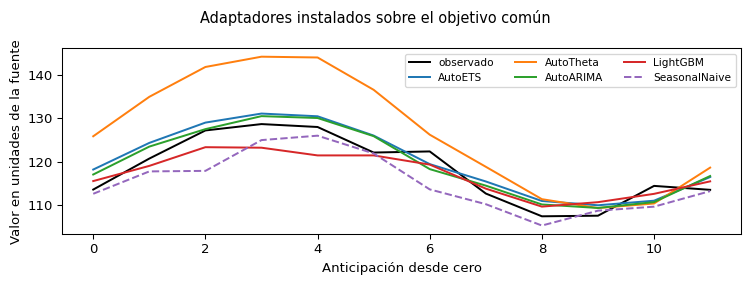

In [7]:
# Compara los adaptadores recién ejecutados y la referencia estacional histórica.
naive, naive_sigma = seasonal_naive(history, m, h)
fig, ax = plt.subplots()
ax.plot(actual, color="black", label='observado')
for label, q in (("AutoETS", ets_q), ("AutoTheta", auto_theta_q), ("AutoARIMA", arima_q), ("LightGBM", tree_q)):
    ax.plot(q[:, 1], label=label)
ax.plot(naive, label="SeasonalNaive", linestyle="--")
ax.set(xlabel='Anticipación desde cero', ylabel='Valor en unidades de la fuente')
ax.legend(ncol=3, fontsize=8)
fig.suptitle('Adaptadores instalados sobre el objetivo común', fontsize=11)
fig.tight_layout()
plt.show()


La figura hace visible el desacuerdo, pero no identifica una causa única. La diferencia entre un árbol y un modelo estadístico puede depender de rezagos, recursión, longitud del contexto, objetivo de ajuste o selección de parámetros. No debe atribuirse automáticamente a mayor capacidad. El corte temporal compartido elimina un factor de confusión, manteniendo diferencias reales entre métodos. Para aislar cada explicación propuesta se requieren ablaciones controladas y criterios declarados antes de evaluar.

La celda siguiente utiliza trayectorias neuronales y preentrenadas congeladas de la traza publicada. Las adaptaciones directas de NLinear, DLinear y NHITS mantienen nombres distintos de las variantes neuralforecast. Chronos-Bolt, Chronos-2, TimesFM y TiRex conservan la procedencia de sus checkpoints. La función de medidas vuelve a ejecutarse sobre esas predicciones con la misma escala y objetivos finales de los adaptadores actuales. Esta celda no entrena redes, descarga checkpoints ni ejecuta inferencia de modelos fundacionales.


In [8]:
# Recalcula puntuaciones de trayectorias conservadas sin atribuirles un ajuste nuevo.
frozen = [row for row in trace["methods"] if row["name"] in
          ("NLinear", "DLinear", "NHITS", "NLinear (nf)", "DLinear (nf)", "NHITS (nf)",
           "Chronos-Bolt", "Chronos-2", "TimesFM-2.5", "TiRex-2")]
frozen_scores = [(row["name"], metrics(history, actual, row["point"], row["lower"], row["upper"], m))
                 for row in frozen]
for name, score in frozen_scores:
    print(name, "MASE", round(score["mase"], 4), 'cobertura', round(score["coverage"], 4))


NHITS (nf) MASE 0.609 cobertura 0.4167
DLinear (nf) MASE 2.9511 cobertura 0.5833
NLinear (nf) MASE 1.3846 cobertura 0.3333
NLinear MASE 0.6563 cobertura 0.6667
DLinear MASE 0.3787 cobertura 0.5833
NHITS MASE 0.531 cobertura 0.4167
Chronos-Bolt MASE 0.7158 cobertura 0.5833
Chronos-2 MASE 0.5327 cobertura 0.5
TimesFM-2.5 MASE 0.5462 cobertura 0.8333
TiRex-2 MASE 0.6389 cobertura 0.8333


Precisión puntual y amplitud responden preguntas diferentes. La segunda figura enfrenta MASE con amplitud media para los modelos archivados. La tabla conserva cobertura para evitar valorar intervalos estrechos sin revisar sus fallos. La amplitud se expresa en unidades de la serie y no debe agregarse directamente entre conjuntos sin relación. Un punto bajo describe este bloque; no demuestra dominancia a través de múltiples orígenes o funciones de costo.


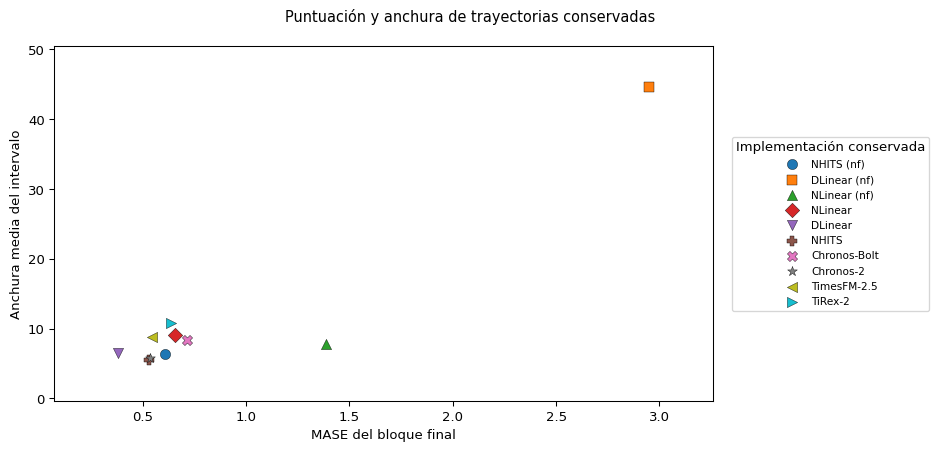

In [9]:
# La relación entre puntuación y anchura conserva el compromiso entre pronóstico puntual e intervalo.
fig, ax = plt.subplots(figsize=(10, 4.8))
markers = ("o", "s", "^", "D", "v", "P", "X", "*", "<", ">")
for index, (name, score) in enumerate(frozen_scores):
    ax.scatter(score["mase"], score["mean_width"], label=name, s=60,
               marker=markers[index % len(markers)], color=plt.get_cmap("tab10")(index),
               edgecolors="black", linewidths=0.3)
ax.set(xlabel='MASE del bloque final', ylabel='Anchura media del intervalo')
ax.margins(x=0.12, y=0.15)
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), title='Implementación conservada', fontsize=8)
fig.suptitle('Puntuación y anchura de trayectorias conservadas', fontsize=11)
fig.tight_layout()
plt.show()


La dispersión revela intercambios que desaparecen en una clasificación única. Dos métodos con errores puntuales semejantes pueden expresar incertidumbres muy diferentes. Un intervalo amplio puede aumentar la cobertura y resultar poco preciso para decidir. Además, tres cuantiles ofrecen una descripción limitada de la distribución. La pérdida ponderada del artefacto promedia esas tres medidas; no integra una distribución completa ni demuestra que todas las probabilidades de las colas sean confiables.

### Sensibilidad al paso de pronóstico

Sea $y_1,\ldots,y_n$ la historia de ajuste y sea $m$ el rezago estacional declarado. La escala de referencia usa diferencias calculadas íntegramente dentro de esa historia.

$$
s_m=\frac{1}{n-m}\sum_{i=m+1}^{n}|y_i-y_{i-m}|.
$$

Con una escala común para todos los métodos, el error absoluto escalado de un conjunto $G$ de pasos es

$$
E_G(f)=\frac{1}{|G|s_m}\sum_{j\in G}|y_{n+j}-\widehat y_{n+j}^{(f)}|.
$$

El conjunto completo da el MASE del bloque reservado. Divida los pasos en dos grupos iguales después de generar las trayectorias originales para el horizonte fijo. La celda aplica esa operación a cada trayectoria puntual recién ejecutada y a la referencia estacional. Conserva el ajuste, el origen, el horizonte y la escala. Un cambio de orden relativo refleja qué observaciones y posiciones entran en la puntuación. Reajustar en un origen posterior incorporaría información nueva y respondería otra pregunta. Cambiar el horizonte también podría modificar el ajuste del adaptador o la forma de construir su trayectoria.


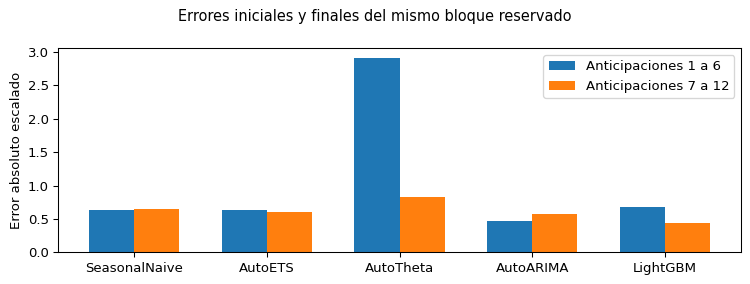

SeasonalNaive inicial y final [0.6393 0.6535]
AutoETS inicial y final [0.6287 0.6008]
AutoTheta inicial y final [2.9087 0.8314]
AutoARIMA inicial y final [0.4742 0.5784]
LightGBM inicial y final [0.6729 0.4439]


In [10]:
# Compara los errores iniciales y finales dentro del mismo bloque reservado.
lead_groups = np.array_split(np.arange(h), 2)
scale = np.mean(np.abs(history[m:] - history[:-m]))
paths = {"SeasonalNaive": naive, "AutoETS": ets_q[:, 1], "AutoTheta": auto_theta_q[:, 1],
         "AutoARIMA": arima_q[:, 1], "LightGBM": tree_q[:, 1]}
scores = np.array([[np.mean(np.abs(actual[group] - path[group])) / scale
                    for group in lead_groups] for path in paths.values()])
fig, ax = plt.subplots()
positions = np.arange(len(paths))
for index, group in enumerate(lead_groups):
    ax.bar(positions + (index - 0.5) * 0.34, scores[:, index], width=0.34,
           label=f"Anticipaciones {group[0] + 1} a {group[-1] + 1}")
ax.set_xticks(positions, list(paths))
ax.set(ylabel='Error absoluto escalado')
ax.legend()
fig.suptitle('Errores iniciales y finales del mismo bloque reservado', fontsize=11)
fig.tight_layout()
plt.show()
for name, pair in zip(paths, scores, strict=True):
    print(name, 'inicial y final', np.round(pair, 4))


### Ajustar y ejecutar referencias neuronales y preentrenadas

Las trayectorias conservadas responden a reproducibilidad, pero no constituyen una ejecución nueva. Llamamos ahora reference_forecasts del producto solo con la misma historia disponible, período y horizonte entregados a los adaptadores instalados. Ajusta realmente NLinear, DLinear y NHITS mediante NeuralForecast fijado, y ejecuta Chronos-Bolt, Chronos-2, TimesFM 2.5 y TiRex-2 con pesos fijados por revisión. Cada modelo devuelve los mismos tres cuantiles y horizonte; actual no es argumento. Este experimento didáctico pequeño no repite los quince casos ni las colecciones externas.

El auxiliar usa el entorno de referencia Linux declarado por separado; en Windows lo aporta la ruta WSL configurada porque TiRex-2 requiere dependencias CUDA de Linux. Prepara el entorno y los modelos mediante el flujo documentado antes de ejecutar. Ninguna celda instala paquetes ni sustituye modelos silenciosamente. Se comprueban versiones y revisiones frente a la procedencia de la comparación fresca conservada, y se rechazan pesos ausentes o identidades distintas. El entorno y las revisiones se devuelven junto a las nuevas trayectorias. Las adaptaciones directas en torch siguen identificadas como resultados conservados: sus cabezas de cuantiles y su diseño NHITS difieren de las implementaciones de referencia mantenidas.

Referencias: NLinear y DLinear, https://arxiv.org/abs/2205.13504; NHITS, https://arxiv.org/abs/2201.12886; paquete https://github.com/Nixtla/neuralforecast; Chronos, https://github.com/amazon-science/chronos-forecasting; TimesFM, https://github.com/google-research/timesfm; TiRex-2, https://huggingface.co/NX-AI/TiRex-2.


SHA-256 de la historia disponible: 7a2e524b01ecb39b74b59a8ccb4b1123de1b8356dfac8f0ad6f94df21a31dcba
NLinear neuralforecast 3.1.9 ajustado con la historia
DLinear neuralforecast 3.1.9 ajustado con la historia
NHITS neuralforecast 3.1.9 ajustado con la historia
Chronos-Bolt chronos-forecasting 2.3.2 772f3d25d38aec6d914c8949dab4462e2d46f5d8
Chronos-2 chronos-forecasting 2.3.2 29ec3766d36d6f73f0696f85560a422f50e8498c
TimesFM-2.5 timesfm 2.0.2 1d952420fba87f3c6dee4f240de0f1a0fbc790e3
TiRex-2 tirex-2 0.1.1 30788a311699acba7e6393ad9700ea7b7cb9bb2d


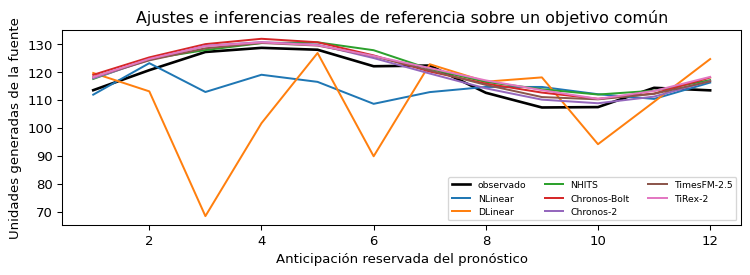

In [11]:
# Envía solo historia disponible al entorno de referencia con versiones comprobadas.
reference_run = reference_forecasts(history, m, h)
print("SHA-256 de la historia disponible:", reference_run["input_sha256"])
for name, row in reference_run["methods"].items():
    print(name, row["package"], row["package_version"], row.get("checkpoint_revision", "ajustado con la historia"))
fig, ax = plt.subplots()
ax.plot(np.arange(1, h + 1), actual, color="black", linewidth=2, label="observado")
for name, row in reference_run["methods"].items():
    q = np.asarray(row["quantiles"])
    ax.plot(np.arange(1, h + 1), q[:, 1], label=name)
ax.set(xlabel="Anticipación reservada del pronóstico", ylabel="Unidades generadas de la fuente")
ax.set_title("Ajustes e inferencias reales de referencia sobre un objetivo común")
ax.legend(ncol=3, fontsize=7)
fig.tight_layout()
plt.show()


Las medianas graficadas provienen de llamadas reales de referencia, con identidades exactas impresas arriba. Sus diferencias frente a trayectorias conservadas pueden depender de implementación, precisión o entorno de ajuste y no deben presentarse como acuerdo. La tabla siguiente puntúa las nuevas trayectorias contra el mismo objetivo y conserva las antiguas en filas separadas. Un ajuste exitoso no prueba repetibilidad entre semillas, independencia del preentrenamiento, calibración ni superioridad general frente a referencias estadísticas económicas.


La tabla numérica puntúa cada trayectoria sobre el mismo bloque y escala histórica. El estado distingue adaptadores recién ajustados, inferencias de referencia ejecutadas y trayectorias adaptadas conservadas. MASE es adimensional, la anchura conserva unidades generadas y la cobertura es una fracción empírica de este bloque. Error bajo e intervalo estrecho no son criterios intercambiables.


In [12]:
# Compara exactitud puntual e intervalos sin mezclar objetivos de evaluación.
table_rows = []
for name, q in (("AutoETS", ets_q), ("AutoTheta", auto_theta_q), ("AutoARIMA", arima_q), ("LightGBM", tree_q)):
    score = metrics(history, actual, q[:, 1], q[:, 0], q[:, 2], m)
    table_rows.append((name, "ejecutado", score["mase"], score["mean_width"], score["coverage"]))
for name, score in frozen_scores:
    table_rows.append((name, "trayectoria conservada", score["mase"], score["mean_width"], score["coverage"]))
for name, row in reference_run["methods"].items():
    q = np.asarray(row["quantiles"])
    score = metrics(history, actual, q[:, 1], q[:, 0], q[:, 2], m)
    table_rows.append((name, "referencia ejecutada", score["mase"], score["mean_width"], score["coverage"]))
print("| Método | Ejecución | MASE | Anchura media | Cobertura |")
print("|---|---|---:|---:|---:|")
for name, status, mase, width, coverage in table_rows:
    print(f"| {name} | {status} | {mase:.6f} | {width:.6f} | {coverage:.6f} |")


| Método | Ejecución | MASE | Anchura media | Cobertura |
|---|---|---:|---:|---:|
| AutoETS | ejecutado | 0.614757 | 6.249343 | 0.583333 |
| AutoTheta | ejecutado | 1.870068 | 14.394184 | 0.500000 |
| AutoARIMA | ejecutado | 0.526274 | 6.674179 | 0.666667 |
| LightGBM | ejecutado | 0.558387 | 6.215360 | 0.666667 |
| NHITS (nf) | trayectoria conservada | 0.609038 | 6.293550 | 0.416667 |
| DLinear (nf) | trayectoria conservada | 2.951097 | 44.543833 | 0.583333 |
| NLinear (nf) | trayectoria conservada | 1.384573 | 7.788675 | 0.333333 |
| NLinear | trayectoria conservada | 0.656278 | 9.111275 | 0.666667 |
| DLinear | trayectoria conservada | 0.378737 | 6.542167 | 0.583333 |
| NHITS | trayectoria conservada | 0.531012 | 5.479233 | 0.416667 |
| Chronos-Bolt | trayectoria conservada | 0.715770 | 8.377583 | 0.583333 |
| Chronos-2 | trayectoria conservada | 0.532691 | 5.744525 | 0.500000 |
| TimesFM-2.5 | trayectoria conservada | 0.546210 | 8.775758 | 0.833333 |
| TiRex-2 | trayectoria conser

Las filas de referencia muestran el error de arquitecturas ajustadas ahora; las conservadas describen trayectorias anteriores sin atribuirles inferencia nueva. Puntuaciones y anchuras utilizan un objetivo común. Compara los nombres de NeuralForecast con sus adaptaciones explícitas en torch sin fundir sus identidades. Estos números finitos no determinan el ganador esperado de otra serie o de un horizonte operativo diferente.


Lea juntas las dos barras de cada método. Las diferencias al final pueden reflejar la recursión, un desacuerdo de tendencia que se acumula o la posición de un máximo difícil. La figura por sí sola no identifica cuál de esas explicaciones corresponde. Revise los pasos exactos en el gráfico anterior de trayectorias antes de atribuirles una causa. Los dos puntajes son dependientes porque las predicciones se emitieron juntas y los objetivos provienen de una serie. Repetir el ejercicio en orígenes con bloques futuros disjuntos aportaría evidencia más sólida. Conserve ambos resultados para cada método, incluso cuando cambie el que obtiene el menor error. Una decisión que actúa solo durante seis pasos puede dar más peso al primer grupo. Declare esa prioridad antes de examinar los puntajes.

### Adapta el análisis a tus propios datos

Elija una serie regularmente espaciada y conserve las marcas temporales, las unidades y los indicadores de valores faltantes. Determine el horizonte a partir de la acción que utilizará el pronóstico. Use la frecuencia de medición para fijar un rezago estacional o declare una escala de un paso cuando falte evidencia de periodicidad. Elija la última fecha de ajuste antes de leer los valores reservados. Guarde la historia contigua completa, los objetivos en orden cronológico y el origen. Compruebe que todos los métodos reciban esa historia y devuelvan el mismo número de pasos en las unidades originales de la variable.

Inspeccione el denominador antes de calcular el MASE. Una recurrencia estacional constante puede dar escala cero. En ese caso informe error absoluto en unidades originales y declare indefinido el error escalado. Omitir esos casos para un solo candidato puede producir una ventaja aparente al cambiar la muestra. Registre las excepciones, los avisos de convergencia y las revisiones de pesos junto a las trayectorias. Si se desconoce el solapamiento con el entrenamiento de un modelo preentrenado, consérvelo como incertidumbre asociada a sus puntajes. Aplique las mismas decisiones a los próximos bloques reservados antes de cambiar el conjunto de métodos. Con ese registro, otro lector puede determinar si una mejora aparente corresponde al método, al diseño de evaluación o a la información disponible en su momento.

Si la variable representa energía por intervalo, sume pronósticos de un bloque de decisión solo después de comprobar la regla de agregación. Sumar cuantiles inferiores marginales generalmente produce un valor distinto al cuantil inferior del total. Para una compra agregada, evalúe la distribución pronosticada del total en bloques históricos definidos para esa decisión.

## Resultados

**Respuesta:** Sobre el mismo bloque sintético de 12 objetivos, AutoARIMA recién ajustado obtiene MASE 0.526274 y Chronos-2 recién ejecutado obtiene 0.532694. AutoARIMA informa un aviso de convergencia, por lo que su puntuación no demuestra haber alcanzado un óptimo. La cobertura nueva de TimesFM-2.5 es 0.833333 en este bloque; no establece cobertura poblacional calibrada. La trayectoria conservada de DLinear directo en torch obtiene MASE 0.378737, mientras la referencia DLinear de NeuralForecast recién ajustada obtiene 2.951097. Estas implementaciones distintas deben mantener identidades separadas. Cuatro adaptadores instalados, siete ajustes o inferencias reales de referencia y trayectorias archivadas puntuadas por separado comparten objetivos y escala, pero tienen distinta procedencia. Este único caso generado no sostiene superioridad general.

La cantidad de métodos no equivale a repeticiones experimentales independientes. Sus errores comparten objetivos y, con frecuencia, supuestos. Una comparación general requiere datos declarados, varios orígenes, incertidumbre que considere la dependencia y presupuestos computacionales. Para extractos reales también debe investigarse el posible solapamiento con preentrenamiento. Conservamos esas obligaciones visibles, sin sustituirlas por un promedio favorable obtenido de una colección seleccionada.

## Resumen

Declare qué se ejecutó, qué se leyó, qué configuración produjo cada trayectoria y qué observaciones definen cada medida. Mantenga separadas adaptaciones y bibliotecas de referencia. Compare calidad puntual, amplitud y cobertura, conservando los resultados negativos. La próxima lección evalúa una combinación contextual fija frente a dos ablaciones con los mismos expertos y un criterio declarado antes de examinar los bloques reservados.

## Referencias

- Escalamiento: https://doi.org/10.1016/j.ijforecast.2006.03.001
- Identidad de Theta: https://robjhyndman.com/papers/Theta.pdf
- Suavizamiento y continuación: https://otexts.com/fpp3/holt-winters.html
- Combinaciones por características: https://doi.org/10.1016/j.ijforecast.2019.02.011
- Ensambles dinámicos: https://doi.org/10.1007/s10994-018-05774-y
